# Machine Learning for Business

## Introduction

Bike-sharing is popular in cities. But the number of rentals changes every day because of weather, season and holidays. This makes planning difficult for companies.
This project uses the UCI Bike Sharing dataset (Fanaee-T and Gama, 2013). It has 731 days of data from Washington D.C. (2011–2012).
Objectives:
Group similar days with K-Means and Hierarchical clustering, and compare them.
Give simple advice to the company.

In [1]:
#So before doing any analysis we need to load the tools.
#Without these libraries we cannot read files, create charts or build models.
#This is always the first step in any data science project.
import pandas as pd #for reading and working with structured data.
import seaborn as sns #for creating clear, informative. 
import matplotlib.pyplot as plt #for charts and graphs.
import numpy as np #for numerical operations and data manipulation
import warnings 
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('day.csv')

In [3]:
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [4]:
df.shape

(731, 16)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB


In [6]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


### Variable types
The dataset contains different types of variables:
- Categorical: season, yr, mnth, holiday, weekday, workingday, weathersit
- Continuous: temp, atemp, hum, windspeed
- Discrete (counts): casual, registered, cnt
- Date: dteday
- Identifier: instant (row number, not used in the analysis)

As we can see, the dataset has 16 columns with categorical, continuous and discrete
variables, which meets the requirement of at least 7 columns of different types.

Then i need to check if i have any missing values. Missing values are important because:

they can reduce model accuracy

they can affect statistical analysis

they must be cleaned before machine learning

In [9]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

I checked and i dont have any missing values

In [10]:
# i will check duplicates to ensure data consistency and reliability.
# Duplicate rows can skew analysis and model training by giving
# certain observations more weight than they deserve.
df.duplicated().sum()

np.int64(0)

I saw The result showed that the dataset contained no duplicate observations; therefore, no rows were removed.

In [11]:
# I converted the date column to date format because pandas reads it as text.
# This is needed to plot the data over time and for the SARIMA model later.
df['dteday'] = pd.to_datetime(df['dteday'])

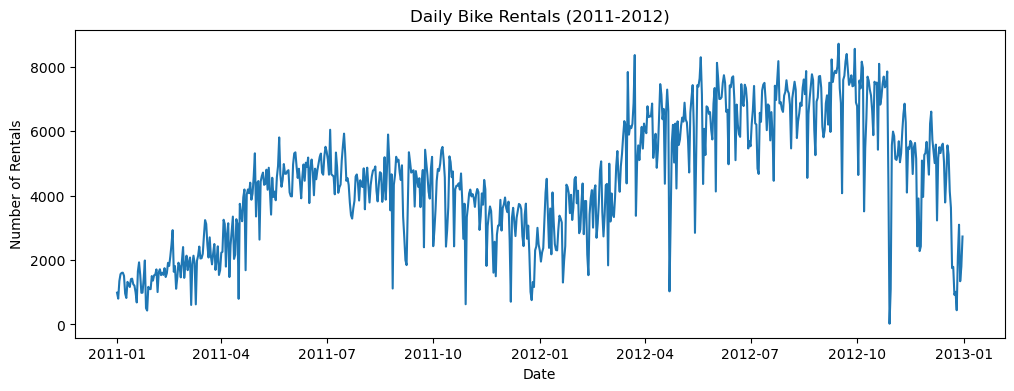

In [12]:
# I used a line plot to see the trend and seasonality of daily rentals.
fig, ax = plt.subplots(figsize = (12, 4))
ax.plot(df['dteday'], df['cnt'])
ax.set_title('Daily Bike Rentals (2011-2012)')
ax.set_xlabel('Date')
ax.set_ylabel('Number of Rentals')
plt.show()

From this plot i see , daily rentals increase from 2011 to 2012, which shows an upward trend. Rentals are higher in summer and lower in winter, which shows a yearly seasonality. There are also some days with very low rentals, probably because of bad weather or holidays.

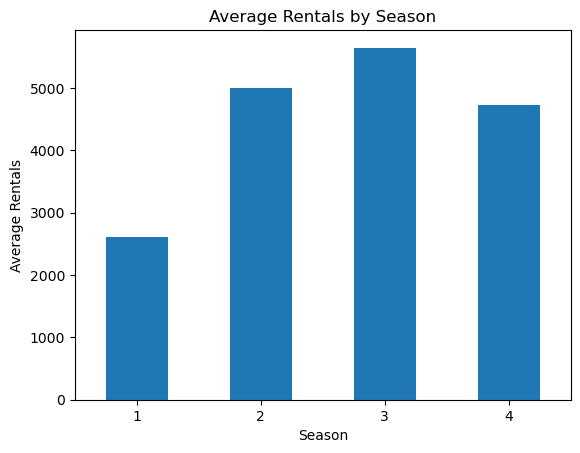

In [13]:
# I used a bar chart to compare the average rentals for each season
# (1 = spring, 2 = summer, 3 = fall, 4 = winter).
# This shows how the season affects demand and will help me describe the clusters later.
season_avg = df.groupby('season')['cnt'].mean()

fig, ax = plt.subplots()
season_avg.plot(kind = 'bar', ax = ax, rot = 0)
ax.set_title('Average Rentals by Season')
ax.set_xlabel('Season')
ax.set_ylabel('Average Rentals')
plt.show()

So from chart , I saw fall (season 3) has the highest average rentals with about 5,600 per day, followed by summer (about 5,000) and winter (about 4,700). Spring (season 1) has the lowest average with about 2,600 rentals per day. This shows that the season has a strong effect on bike demand, with more rentals in warmer months.

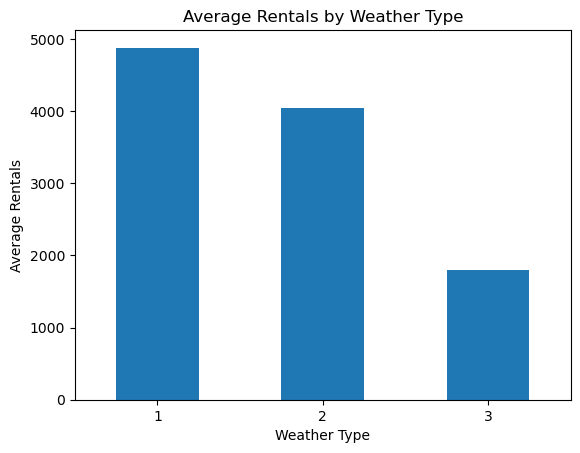

In [14]:
# I used a bar chart to compare the average rentals for each weather type
# (1 = clear, 2 = mist/cloudy, 3 = light rain/snow).
# This shows how bad weather reduces demand, which supports my business problem.
weather_avg = df.groupby('weathersit')['cnt'].mean()

fig, ax = plt.subplots()
weather_avg.plot(kind = 'bar', ax = ax, rot = 0)
ax.set_title('Average Rentals by Weather Type')
ax.set_xlabel('Weather Type')
ax.set_ylabel('Average Rentals')
plt.show()

so from this table i see, clear days (weather 1) have the highest average rentals with about 4,900 per day,followed by misty or cloudy days (about 4,000).On days with light rain or snow (weather 3), rentals drop to about 1,800,which is less than half of clear days.There are no days with heavy rain (weather 4) in the daily dataset.This shows that bad weather strongly reduces bike demand.

In [15]:
# I used a correlation table to see which variables are linked to rentals.
# This is important because if two variables are almost the same
# (like temp and atemp), I should keep only one for clustering,
# otherwise temperature would count twice.
cols = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
print(df[cols].corr().round(2))

            temp  atemp   hum  windspeed  casual  registered   cnt
temp        1.00   0.99  0.13      -0.16    0.54        0.54  0.63
atemp       0.99   1.00  0.14      -0.18    0.54        0.54  0.63
hum         0.13   0.14  1.00      -0.25   -0.08       -0.09 -0.10
windspeed  -0.16  -0.18 -0.25       1.00   -0.17       -0.22 -0.23
casual      0.54   0.54 -0.08      -0.17    1.00        0.40  0.67
registered  0.54   0.54 -0.09      -0.22    0.40        1.00  0.95
cnt         0.63   0.63 -0.10      -0.23    0.67        0.95  1.00


i saw from this table, temp and atemp have a correlation of 0.99, which means they are almost the same variable. Therefore, I will keep only temp for clustering.Temperature has a strong positive correlation with rentals (0.63), which means more people rent bikes on warmer days. Windspeed has a weak negative correlation (-0.23),and humidity has almost no correlation (-0.10) with rentals.Casual and registered are highly correlated with cnt because cnt is the sum of casual and registered users, so they will not be used together in clustering.